# PRÉ-PROCESSAMENTO COM O DATASET ZOO

Dataset obtido via repositório UCI Machine Learning (`ucimlrepo`).
Seguindo as etapas de pré-processamento de dados: exploração técnica, verificação de dados faltantes e tratamento de outliers com método IQR e capping.

In [1]:
# 0. Importando as Bibliotecas Necessárias
import ssl
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

# Ajuste de contexto SSL para download do dataset sem bloqueios de certificado
ssl._create_default_https_context = ssl._create_unverified_context

# Configurando o estilo dos gráficos para melhor visualização
sns.set_style('whitegrid')

## Passo 1: Investigando a Cena do Crime (os Dados)
Carregamos o dataset Zoo (ID: 111) e inspecionamos as primeiras linhas, resumo técnico e registros faltantes.

In [2]:
# Carregando o dataset Zoo (ID: 111)
zoo = fetch_ucirepo(id=111)
df_zoo = zoo.data.original.copy()

print("As 5 primeiras amostras do dataset:")
df_zoo.head()

As 5 primeiras amostras do dataset:


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


In [3]:
# Resumo técnico do dataset
print("Relatório técnico do dataset:")
df_zoo.info()

Relatório técnico do dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   animal_name  101 non-null    object
 1   hair         101 non-null    int64 
 2   feathers     101 non-null    int64 
 3   eggs         101 non-null    int64 
 4   milk         101 non-null    int64 
 5   airborne     101 non-null    int64 
 6   aquatic      101 non-null    int64 
 7   predator     101 non-null    int64 
 8   toothed      101 non-null    int64 
 9   backbone     101 non-null    int64 
 10  breathes     101 non-null    int64 
 11  venomous     101 non-null    int64 
 12  fins         101 non-null    int64 
 13  legs         101 non-null    int64 
 14  tail         101 non-null    int64 
 15  domestic     101 non-null    int64 
 16  catsize      101 non-null    int64 
 17  type         101 non-null    int64 
dtypes: int64(17), object(1)
memory usage: 14

In [4]:
# Contagem de registros corrompidos (dados faltantes)
print("Contagem de registros faltantes por coluna:")
df_zoo.isnull().sum()

Contagem de registros faltantes por coluna:


animal_name    0
hair           0
feathers       0
eggs           0
milk           0
airborne       0
aquatic        0
predator       0
toothed        0
backbone       0
breathes       0
venomous       0
fins           0
legs           0
tail           0
domestic       0
catsize        0
type           0
dtype: int64

## Passo 2: Consertando as Medidas Faltantes
Estratégia de cálculo de mediana para colunas numéricas e preenchimento de eventuais dados faltantes via `.fillna()`.

In [5]:
colunas_numericas = df_zoo.select_dtypes(include=[np.number]).columns
medianas = df_zoo[colunas_numericas].median()

df_zoo.fillna(medianas, inplace=True)

print("Verificação após o primeiro conserto (dados faltantes):")
df_zoo.isnull().sum()

Verificação após o primeiro conserto (dados faltantes):


animal_name    0
hair           0
feathers       0
eggs           0
milk           0
airborne       0
aquatic        0
predator       0
toothed        0
backbone       0
breathes       0
venomous       0
fins           0
legs           0
tail           0
domestic       0
catsize        0
type           0
dtype: int64

## Passo 3: Encontrando Outliers
No dataset Zoo, os atributos de características físicas são predominantemente binários (0 ou 1: pelo, pena, ovos, etc.).
A coluna `legs` (número de patas/pernas) é uma medida contínua/discreta variando de 0 a 8 pernas, ideal para análise de outliers.

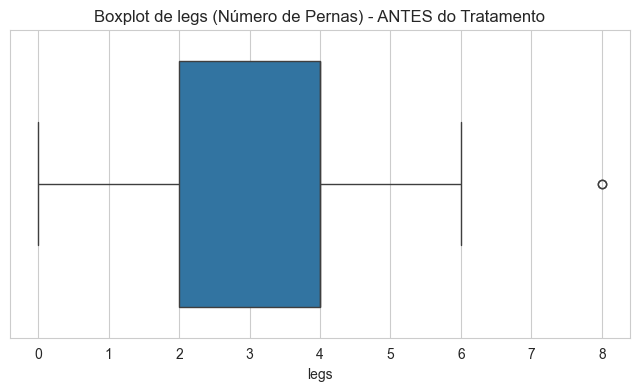

In [6]:
# Boxplot do atributo legs ANTES do tratamento
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_zoo['legs'])
plt.title('Boxplot de legs (Número de Pernas) - ANTES do Tratamento')
plt.show()

In [7]:
# Análise de outliers via método IQR
Q1 = df_zoo['legs'].quantile(0.25)
Q3 = df_zoo['legs'].quantile(0.75)
IQR = Q3 - Q1

limite_superior = Q3 + 1.5 * IQR
limite_inferior = Q1 - 1.5 * IQR

outliers = df_zoo[(df_zoo['legs'] > limite_superior) | (df_zoo['legs'] < limite_inferior)]
outliers_count = outliers.shape[0]

print(f"Q1 (25%): {Q1}")
print(f"Q3 (75%): {Q3}")
print(f"IQR: {IQR}")
print(f"Limite superior para outliers: {limite_superior:.2f}")
print(f"Total de outliers identificados: {outliers_count}")

if outliers_count > 0:
    print("\nAnimais considerados outliers estatísticos pelo método IQR:")
    display(outliers[['animal_name', 'legs']])

Q1 (25%): 2.0
Q3 (75%): 4.0
IQR: 2.0
Limite superior para outliers: 7.00
Total de outliers identificados: 2

Animais considerados outliers estatísticos pelo método IQR:


,animal_name,legs
53,octopus,8
72,scorpion,8


In [8]:
# Tratamento com Capping (substituindo valores acima do limite superior)
df_zoo_capped = df_zoo.copy()
df_zoo_capped['legs'] = np.where(
    df_zoo_capped['legs'] > limite_superior,
    limite_superior,
    df_zoo_capped['legs']
)
print("Outliers em 'legs' tratados com sucesso via técnica de Capping.")

Outliers em 'legs' tratados com sucesso via técnica de Capping.


## Passo 4: Inspeção Final
Verificamos a nova distribuição com o boxplot após o capping e as estatísticas descritivas finais.

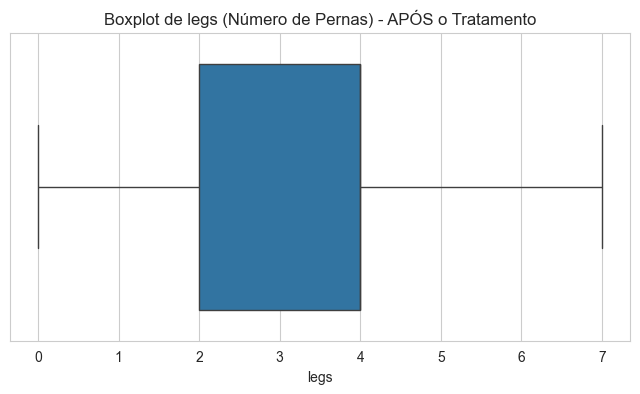

In [9]:
# Boxplot de legs APÓS o tratamento
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_zoo_capped['legs'])
plt.title('Boxplot de legs (Número de Pernas) - APÓS o Tratamento')
plt.show()

In [10]:
# Estatísticas descritivas do dataset limpo
print("Estatísticas descritivas do dataset Zoo limpo:")
df_zoo_capped.describe()

Estatísticas descritivas do dataset Zoo limpo:


,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,type
count,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000
mean,0.425743,0.198020,0.584158,0.405941,0.237624,0.356436,0.554455,0.603960,0.821782,0.792079,0.079208,0.168317,2.821782,0.742574,0.128713,0.435644,2.831683
std,0.496921,0.400495,0.495325,0.493522,0.427750,0.481335,0.499505,0.491512,0.384605,0.407844,0.271410,0.376013,1.986938,0.439397,0.336552,0.498314,2.102709
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,1.000000
50%,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,0.000000,2.000000
75%,1.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,4.000000,1.000000,0.000000,1.000000,4.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,7.000000,1.000000,1.000000,1.000000,7.000000


## Passo 5: Codificação das Variáveis Categóricas
A coluna `class_type` representa categorias sem ordem numérica e é convertida com One-Hot Encoding. `animal_name` é apenas um identificador, então não é usado como característica do modelo.

In [11]:
# animal_name identifica cada animal; não é uma característica para o modelo.
# class_type representa classes sem ordem numérica, então usamos One-Hot Encoding.
df_zoo_codificado = df_zoo_capped.drop(columns=['animal_name']).copy()
df_zoo_codificado['class_type'] = df_zoo_codificado['class_type'].astype('category')
df_zoo_codificado = pd.get_dummies(
    df_zoo_codificado,
    columns=['class_type'],
    prefix='class_type',
    dtype=int
)

print("Dataset com a variável de classe codificada:")
display(df_zoo_codificado.head())
print(f"\nDimensões após a codificação: {df_zoo_codificado.shape}")

KeyError: 'class_type'